# SnapWave vs SWAN: dynamic cases

The hourly reference runs of notebook 08 in both models, to help select a model
for the Netherlands. Run it any time: it uses the SWAN hours finished so far and
the same hours of SnapWave (`SnapWave_CASES_Dynamic`, already postprocessed).

**Forcing**: the same offshore waves at every goal and the same ERA5 wind in both.
**Water level differs**: SnapWave takes one value per goal, SWAN one level per
case, their mean, so part of the difference at shallow sites comes from there.

The metrics of sections 2 to 5 take SnapWave as the reference (bias = SWAN −
SnapWave) by convention only. Section 6, against the **buoys**, is the one that
shows which model is closer to the sea.

In [ ]:
import os
import sys

# Must run before any GDAL-touching import (geopandas/pyogrio, rasterio/rioxarray).
# When the kernel is launched without going through `conda activate` (e.g. VS
# Code's Jupyter extension), GDAL_DATA/PROJ_DATA are unset, and importing
# rioxarray/rasterio before geopandas.read_file() in that state leaves GDAL's
# data-path auto-discovery broken for pyogrio, raising:
#   ValueError: Found GDAL data directory at .../share/gdal but it does not
#   appear to correctly contain GDAL data files
# Setting these explicitly sidesteps the broken auto-discovery.
os.environ.setdefault("GDAL_DATA", os.path.join(sys.prefix, "share", "gdal"))
os.environ.setdefault("PROJ_DATA", os.path.join(sys.prefix, "share", "proj"))

import numpy as np
from utils import model_comparison as mc
from utils import validation as val
from utils.config import get_offshore_wave, open_offshore_waves

## Configuration

In [2]:
offshore_name = "WHACS_cal"
wind = True  # the dynamic runs with or without wind (08 use_wind)
period = "2013"
drop_suspect_hours = True  # the unstable SnapWave hours of section 1

## 1 · Load the cases

In [ ]:
snapwave = mc.load_snapwave_dynamic(offshore_name, wind, period)
swan = mc.load_swan(snapwave)
snapwave = snapwave.sel(time=swan.time)
offshore = open_offshore_waves(entry=get_offshore_wave(offshore_name))
offshore_hs = offshore["hs"].sel(time=swan.time).load()
print(
    f"{swan.sizes['time']} SWAN hours finished: {swan.time.values[0]} to {swan.time.values[-1]}"
)

2097 SWAN hours finished: 2013-01-01T00:00:00.000000000 to 2013-04-01T01:00:00.000000000


SnapWave has unstable hours: Hs of 5-10 m at thousands of sites under about 0.5 m
offshore, changing from one hour to the next. They are not sea states, so by
default they leave both models here (`drop_suspect_hours`).

In [4]:
suspect = mc.suspect_hours(snapwave["hs"], offshore_hs)
print(f"{int(suspect.sum())} suspect SnapWave hours of {suspect.size}")
if drop_suspect_hours:
    keep = ~suspect.values
    snapwave, swan, offshore_hs = (
        snapwave.isel(time=keep),
        swan.isel(time=keep),
        offshore_hs.isel(time=keep),
    )

49 suspect SnapWave hours of 2097


## 2 · Metrics per site group

The array runs in time order: while it is running, these hours cover only the
first part of the year.

In [ ]:
comparison = val.compare(
    snapwave,
    swan,
    variables=mc.VARIABLES,
    reference_label="SnapWave",
    estimate_label="SWAN",
)
columns = ["n", "bias", "rmse", "r2"]
comparison.metrics.query("site_source != 'buoy'").set_index(["group", "variable"])[
    columns
].round(3)

n   bias    rmse     r2
group    variable                               
5m       hs        2397075 -0.266   0.348  0.477
         tp        2396518  0.469   1.916 -1.109
         dir       2397075 -1.482  27.762  0.760
         spr       2397075 -0.036  10.195  0.523
10m      hs        3839997 -0.303   0.382  0.592
         tp        3839562 -0.102   1.659 -0.604
         dir       3839997 -2.187  27.377  0.804
         spr       3839997 -0.192   9.289  0.417
20m      hs        3946496 -0.284   0.354  0.759
         tp        3945947 -0.271   1.465 -0.212
         dir       3946496 -0.966  17.717  0.928
         spr       3946496  1.783   7.266  0.468
DeenHaag hs         288768 -0.270   0.331  0.723
         tp         288759 -0.279   1.398 -0.009
         dir        288768 -2.531  20.508  0.883
         spr        288768  1.936   8.370  0.394

In [ ]:
# Median over the buoy sites
comparison.metrics.query("site_source == 'buoy'").groupby("variable")[
    columns
].median().round(3)

,n,bias,rmse,r2
variable,,,,
dir,2048.0,-0.645,18.905,0.920
hs,2048.0,-0.283,0.341,0.728
spr,2048.0,1.535,7.974,0.391
tp,2048.0,-0.311,1.381,-0.229


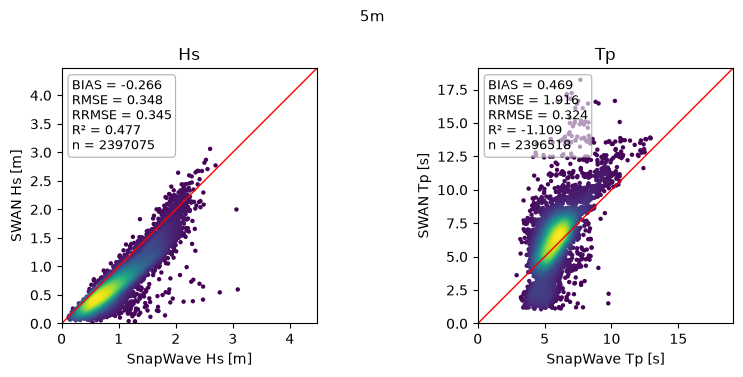

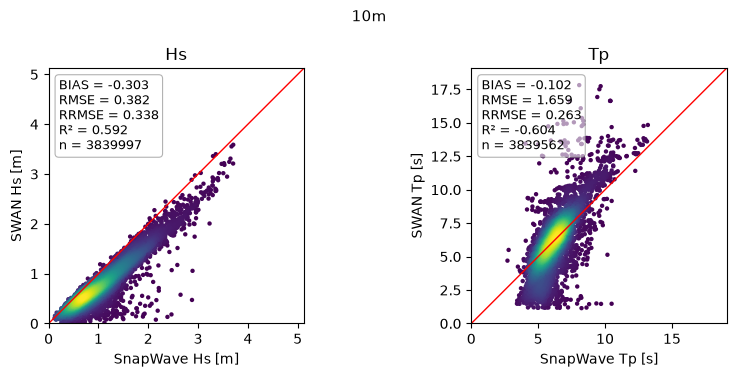

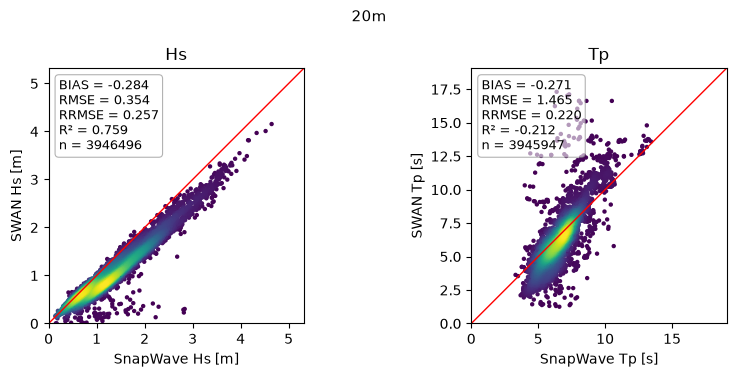

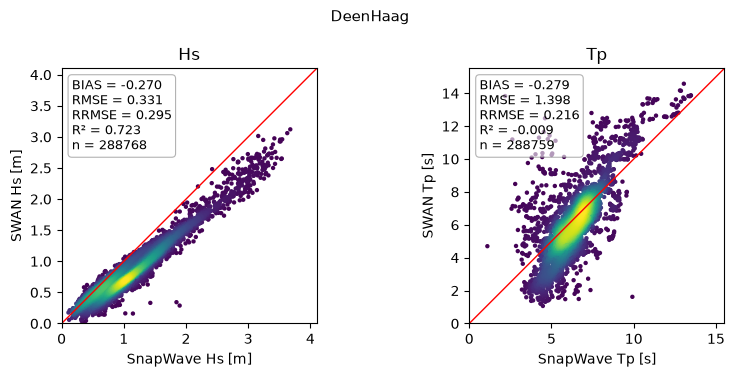

In [7]:
for group in ["5m", "10m", "20m", "DeenHaag"]:
    comparison.plot_scatter(group, variables=["hs", "tp"])

## 3 · Hs by sea state and wind

In [ ]:
mc.hs_by_class(
    snapwave["hs"], swan["hs"], snapwave["hs"], [0, 0.5, 1, 2, 3, 5, 15]
).round(3)

,ratio,n,bias,rmse,rrmse,si,r,r2
class,,,,,,,,
0-0.5,0.798,1016996,-0.086,0.128,0.345,0.249,0.562,-0.908
0.5-1,0.747,3784444,-0.209,0.259,0.342,0.199,0.547,-2.437
1-2,0.772,4565140,-0.350,0.410,0.291,0.149,0.769,-1.184
2-3,0.821,1002770,-0.446,0.534,0.226,0.123,0.633,-2.694
3-5,0.841,180746,-0.550,0.594,0.177,0.067,0.820,-2.767
5-15,0.890,64,-0.554,0.558,0.111,0.013,0.169,-926.385


In [ ]:
# Per hour: offshore Hs over the goals
mc.hs_by_class(
    snapwave["hs"], swan["hs"], offshore_hs.mean("goal"), [0, 1, 2, 3, 5, 15]
).round(3)

,ratio,n,bias,rmse,rrmse,si,r,r2
class,,,,,,,,
0-1,0.756,2647834,-0.161,0.225,0.355,0.229,0.794,0.240
1-2,0.761,4600209,-0.290,0.348,0.315,0.164,0.866,0.158
2-3,0.789,2632297,-0.384,0.453,0.277,0.139,0.910,0.376
3-5,0.851,669820,-0.375,0.484,0.207,0.124,0.919,0.610
5-15,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# Per hour: wind speed over the case area
wind_speed = mc.mean_wind_speed(swan.time)
mc.hs_by_class(snapwave["hs"], swan["hs"], wind_speed, [0, 5, 8, 11, 14, 40]).round(3)

,ratio,n,bias,rmse,rrmse,si,r,r2
class,,,,,,,,
0-5,0.808,2972420,-0.156,0.221,0.304,0.195,0.889,0.584
5-8,0.772,4249943,-0.289,0.345,0.306,0.154,0.912,0.429
8-11,0.779,2689050,-0.410,0.472,0.290,0.134,0.930,0.448
11-14,0.852,638747,-0.356,0.464,0.226,0.136,0.928,0.648
14-40,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN


## 4 · Hs ratio per site

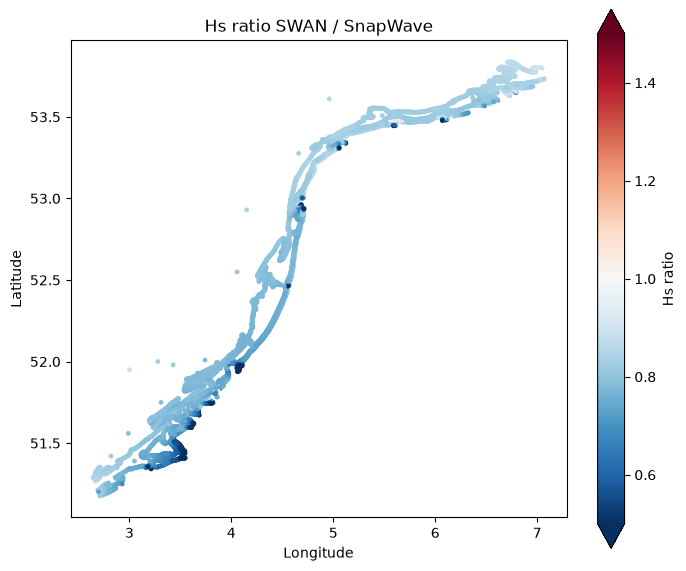

In [11]:
mc.plot_site_ratio(mc.hs_ratio(snapwave["hs"], swan["hs"], "time"));

## 5 · Grid maps

The hours with a map in both models: the strongest, and the largest disagreement
in energy.

93 hours with a map in both models


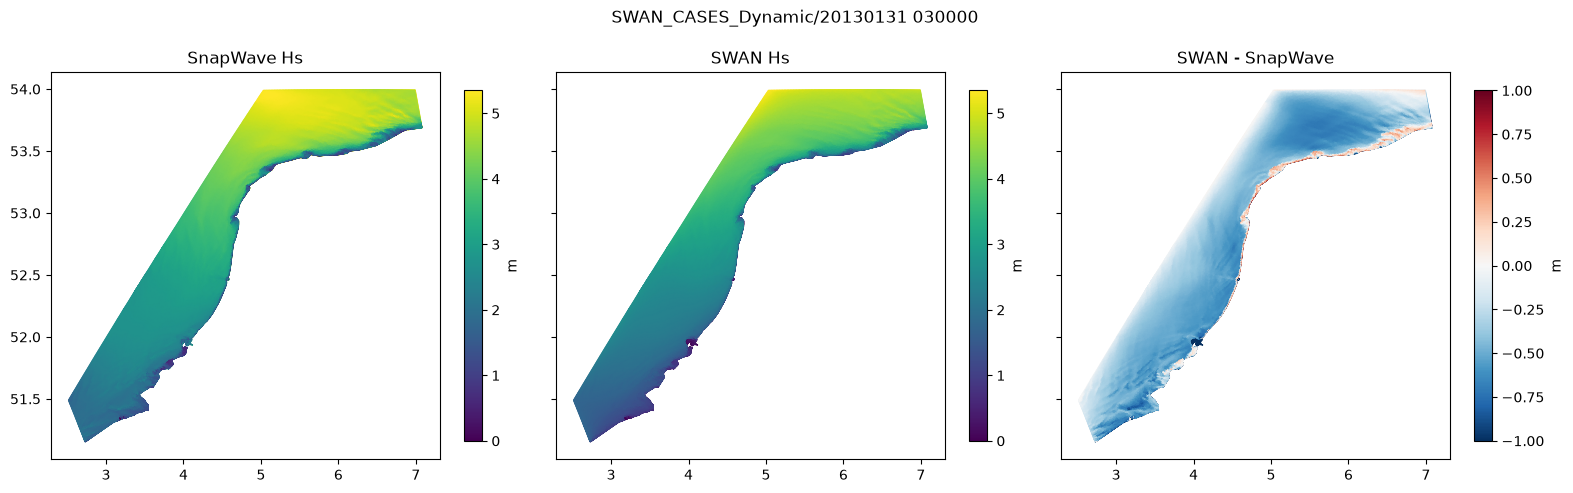

In [12]:
rows = mc.map_rows(snapwave)
folders = mc.case_folders(snapwave)
print(f"{len(rows)} hours with a map in both models")

strongest = snapwave["hs"].sel(time=rows).mean("sites").idxmax().values
mc.plot_map_comparison(folders[strongest]);

ratio 0.39


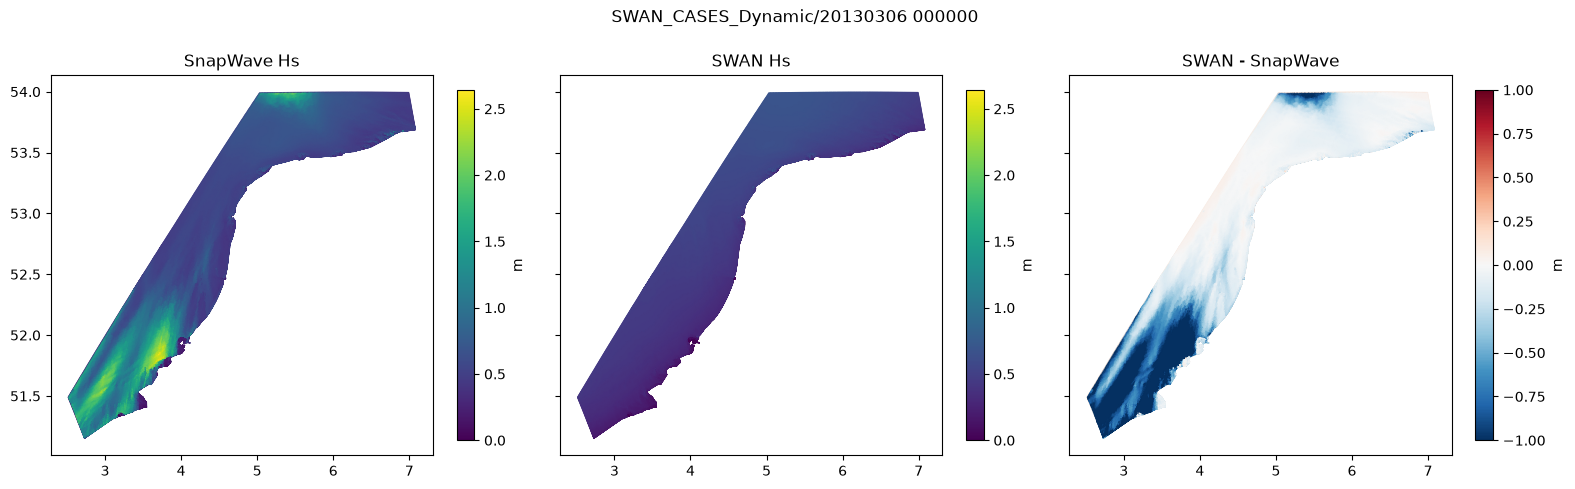

In [13]:
ratio = mc.hs_ratio(snapwave["hs"], swan["hs"], "sites").sel(time=rows)
furthest = abs(np.log(ratio)).idxmax().values
print(f"ratio {float(ratio.sel(time=furthest)):.2f}")
mc.plot_map_comparison(folders[furthest]);

## 6 · Against the buoys

Both models on the same hours and buoys. Tp is flat in SnapWave (one period per
node) and direction and spreading exist at few buoys: read the `n` column.

In [14]:
hours = slice(swan.time.values[0], swan.time.values[-1])
buoy = val.load_buoy_observations(hours, variables=mc.VARIABLES)
sites = list(buoy.sites.values)
models = {"SnapWave": snapwave.sel(sites=sites), "SWAN": swan.sel(sites=sites)}
results = val.compare_all(buoy, models, variables=mc.VARIABLES, reference_label="Buoy")
summary = val.metrics_summary(results)
print(f"{len(sites)} buoys")
summary.groupby(["variable", "model"])[columns].median().round(3)

27 buoys


n   bias    rmse     r2
variable model                                 
dir      SWAN      1728.0  5.963  21.917  0.862
         SnapWave  1728.0  6.437  24.032  0.833
hs       SWAN      2035.0 -0.068   0.231  0.847
         SnapWave  2035.0  0.222   0.322  0.709
spr      SWAN         0.0 -5.657  10.417 -0.283
         SnapWave     0.0 -6.764  11.853 -0.691
tp       SWAN      2035.0  0.201   1.700  0.150
         SnapWave  2035.0  0.447   1.554  0.255

In [ ]:
# Hs per buoy: negative = SWAN closer to the buoy
hs = summary.query("variable == 'hs'").pivot(
    index="group", columns="model", values="rmse"
)
hs.assign(difference=hs["SWAN"] - hs["SnapWave"]).sort_values("difference").round(3)

model,SWAN,SnapWave,difference
group,,,
buoy_Amelander31,0.157,0.566,-0.408
buoy_WielingenNoord,0.178,0.385,-0.207
buoy_IJgeul,0.185,0.383,-0.198
buoy_CadzandBoei,0.162,0.348,-0.186
buoy_AWG,0.163,0.348,-0.185
buoy_L91,0.237,0.393,-0.156
buoy_StortemelkWest,0.263,0.418,-0.155
buoy_Deurlo,0.180,0.310,-0.130
buoy_ScheurWest,0.186,0.315,-0.129


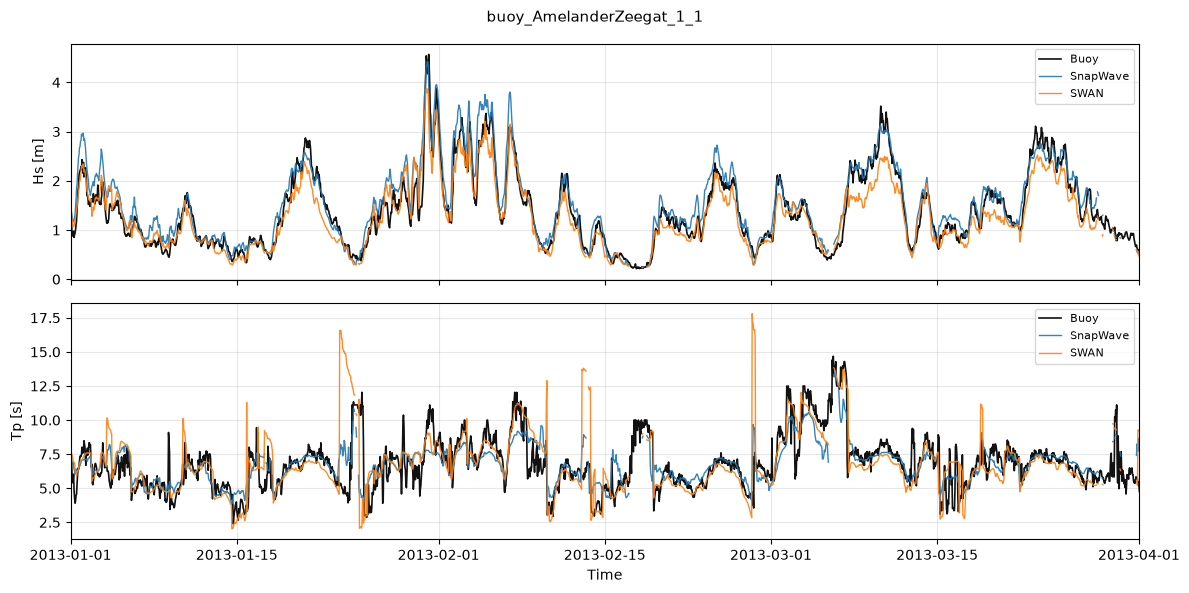

In [16]:
# Buoy with the longest Hs record in these hours
site = buoy["hs"].notnull().sum("time").idxmax().item()
val.plot_buoy_timeseries(buoy, models, site, variables=["hs", "tp"]);

## 7 · Cost per case

In [17]:
mc.runtimes(snapwave)

,SnapWave,SWAN
count,300.000000,300.000000
50%,2.666667,43.166667
max,7.816667,53.083333
